# MLP in PyTorch (TP05)
A dense network on the paintings: first the 1-hidden-layer sigmoid network of TP05 Part A, then a tuned ReLU network (TP05 Exercise 20).

In [2]:
import os
os.chdir("..")                      # run from the repo root, where data/ and splits/ are

import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import confusion_matrix

from museum_guide.data import load_images, get_dataloaders

np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(2)
device = "cuda" if torch.cuda.is_available() else "cpu"

EPOCHS_A = 10                               # epochs for the Part A network
BATCH_SIZE = 128
LR = 0.2                                    # SGD learning rate of Part A
CLASSES = ["Baroque", "Cubism", "Impressionism", "Pop_Art", "Ukiyo_e"]
print("device:", device)

device: cpu


In [3]:
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += loss_fn(logits, yb).item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return total_loss / total, correct / total


def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    running, total = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item() * len(yb)
        total += len(yb)
    return running / total


def fit(model, train_loader, val_loader, loss_fn, optimizer, n_epochs, verbose=True):
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(n_epochs):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if verbose:
            print(f"epoch {epoch + 1:2d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.3f}")
    return history


def show_images(images, titles, n=10):
    fig, axes = plt.subplots(1, n, figsize=(1.5 * n, 1.9))
    for ax, img, title in zip(axes, images[:n], titles[:n]):
        ax.imshow(img.permute(1, 2, 0).cpu())          # colour image: (3, H, W) -> (H, W, 3)
        ax.set_title(title, fontsize=8)
        ax.axis("off")
    plt.show()

In [4]:
train_loader, val_loader, test_loader = get_dataloaders("mlp", batch_size=BATCH_SIZE)
X, y, meta = load_images()
split = pd.read_csv("splits/split.csv")
X_test_raw = X[torch.tensor((split["split"] == "test").values)]     # test images in [0, 1], to look at them
xb, yb = next(iter(train_loader))
print("one batch:", tuple(xb.shape), tuple(yb.shape), "| batches per epoch:", len(train_loader))

split          test  train  val
label                          
Baroque          52    197   51
Cubism           53    204   43
Impressionism    57    188   55
Pop_Art          52    191   57
Ukiyo_e          36    220   44
Split validated!
one batch: (128, 3, 64, 64) (128,) | batches per epoch: 8


In [5]:
torch.manual_seed(0)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(3 * 64 * 64, 128),
    nn.Sigmoid(),
    nn.Linear(128, 5)
).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print("parameters:", n_params)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=12288, out_features=128, bias=True)
  (2): Sigmoid()
  (3): Linear(in_features=128, out_features=5, bias=True)
)
parameters: 1573637


In [6]:
torch.manual_seed(0)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=LR)
epochs = EPOCHS_A
history_a = fit(model, train_loader, val_loader, loss_fn, optimizer, epochs)

epoch  1 | train loss 1.5574 | val loss 1.5280 | val acc 0.316
epoch  2 | train loss 1.4520 | val loss 1.4866 | val acc 0.384
epoch  3 | train loss 1.4097 | val loss 1.5167 | val acc 0.344
epoch  4 | train loss 1.3646 | val loss 1.4888 | val acc 0.372
epoch  5 | train loss 1.2920 | val loss 1.5001 | val acc 0.416
epoch  6 | train loss 1.3180 | val loss 1.5248 | val acc 0.348
epoch  7 | train loss 1.2217 | val loss 1.5412 | val acc 0.372
epoch  8 | train loss 1.1511 | val loss 1.5227 | val acc 0.404
epoch  9 | train loss 1.1346 | val loss 1.5459 | val acc 0.392
epoch 10 | train loss 1.1213 | val loss 2.0156 | val acc 0.296


In [11]:
test_loss, test_acc = evaluate(model, test_loader, loss_fn)
print(f"test accuracy of the Part A network: {test_acc:.3f}")

test accuracy of the Part A network: 0.288


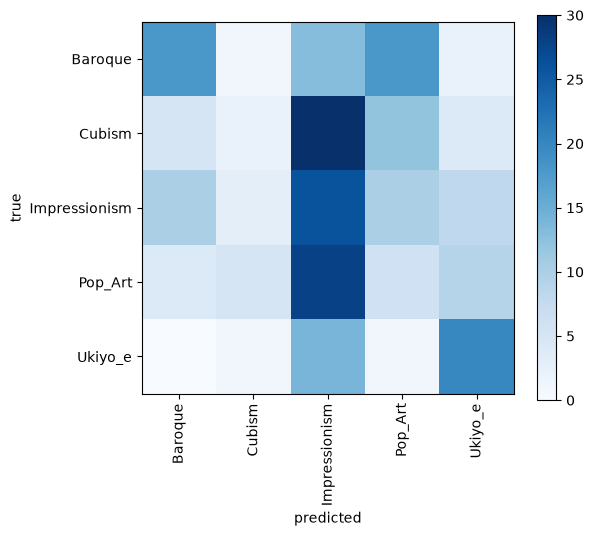

most frequent mistake: Cubism predicted as Impressionism (30 times)


In [7]:
preds = []
true_labels = []
with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        logits = model(xb)
        preds.append(logits.argmax(dim=1).cpu())
        true_labels.append(yb)
preds = torch.cat(preds)
true_labels = torch.cat(true_labels)
cm = confusion_matrix(true_labels, preds, labels=range(5))
off = cm.copy()
np.fill_diagonal(off, 0)
true_cls, pred_cls = np.unravel_index(off.argmax(), off.shape)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(5), CLASSES, rotation=90); plt.yticks(range(5), CLASSES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.colorbar(); plt.show()
print(f"most frequent mistake: {CLASSES[true_cls]} predicted as {CLASSES[pred_cls]} ({cm[true_cls, pred_cls]} times)")

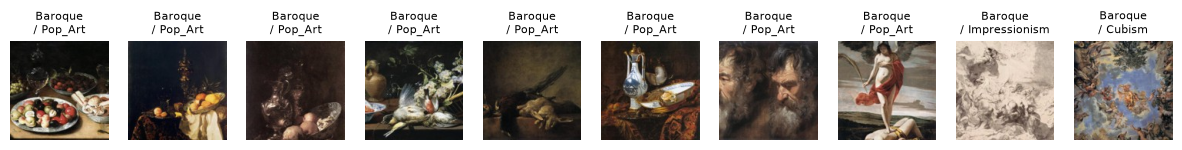

In [8]:
wrong = (preds != true_labels).nonzero(as_tuple=True)[0]
pred = preds[wrong]
show_images(X_test_raw[wrong], [f"{CLASSES[true_labels[i]]}\n/ {CLASSES[preds[i]]}" for i in wrong[:10]])

In [9]:
def init_weights(model, kind):
    for m in model:
        if isinstance(m, nn.Linear):
            if kind == "zeros":
                nn.init.zeros_(m.weight)
            elif kind == "small":
                nn.init.normal_(m.weight, mean=0.0, std=0.01)
            elif kind == "large":
                nn.init.normal_(m.weight, mean=0.0, std=1.0)
            elif kind == "xavier":
                nn.init.xavier_normal_(m.weight)
            elif kind == "he":
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
            nn.init.zeros_(m.bias)
    return model

In [12]:
epochs_gf = 12
torch.manual_seed(0)
model_gf = nn.Sequential(
    nn.Flatten(),
    nn.Linear(3 * 64 * 64, 256), nn.ReLU(),
    nn.Linear(256, 128), nn.ReLU(),
    nn.Linear(128, 64), nn.ReLU(),
    nn.Linear(64, 5)
).to(device)
model_gf = init_weights(model_gf, "he")
optimizer = torch.optim.Adam(model_gf.parameters(), lr=1e-3)
history_gf = fit(model_gf, train_loader, val_loader, loss_fn, optimizer, epochs_gf)
test_loss_gf, test_acc_gf = evaluate(model_gf, test_loader, loss_fn)
print(f"test accuracy: {test_acc_gf:.3f} (Part A network: {test_acc:.3f}, baseline: 0.372)")

epoch  1 | train loss 5.7161 | val loss 4.5657 | val acc 0.304
epoch  2 | train loss 3.8763 | val loss 4.2176 | val acc 0.340
epoch  3 | train loss 2.5367 | val loss 2.5117 | val acc 0.328
epoch  4 | train loss 1.9099 | val loss 2.4543 | val acc 0.336
epoch  5 | train loss 1.0665 | val loss 2.6391 | val acc 0.356
epoch  6 | train loss 0.7823 | val loss 2.4565 | val acc 0.360
epoch  7 | train loss 0.6230 | val loss 2.5071 | val acc 0.348
epoch  8 | train loss 0.4851 | val loss 2.6157 | val acc 0.340
epoch  9 | train loss 0.3393 | val loss 2.5317 | val acc 0.388
epoch 10 | train loss 0.3400 | val loss 2.6439 | val acc 0.408
epoch 11 | train loss 0.4089 | val loss 3.0294 | val acc 0.360
epoch 12 | train loss 0.2816 | val loss 2.8246 | val acc 0.380
test accuracy: 0.424 (Part A network: 0.288, baseline: 0.372)


## Conclusion
- Part A network (1 hidden sigmoid layer, SGD lr 0.2): test accuracy 0.288, below the baseline. The validation accuracy jumps from epoch to epoch (0.30 to 0.42): the learning rate is too large, and we kept the last epoch, not the best one (0.416 at epoch 5).
- Tuned ReLU network (3 hidden layers, He, Adam): test accuracy 0.424, above the baseline (0.372) but only by a few points (about ±3 points of noise with 250 test images).
- It overfits: train loss 0.28 but validation loss rising from epoch 4 (3.2 million parameters for 1 000 images).
- Most frequent mistake: Cubism predicted as Impressionism (30 times). A dense network sees pixels at fixed positions, not shapes or brush strokes.
- Chance level: 0.20.